# EcoSort Waste Management Assistant
# Module 8 Summative Lab

## Overview

You are a data scientist at "EcoSort," a technology company that specializes in developing AI solutions for waste management. EcoSort has partnered with Metro City's waste management department to develop an intelligent waste management assistant that can help residents properly dispose of waste items so less time is spent sorting material at facilities.

This assistant needs to:

1. Identify waste materials from images uploaded by residents (CNN)
2. Classify waste items based on text descriptions provided by residents (RNN/Transformer)
3. Generate specific recycling instructions based on identified waste type and city policies (Generative Transformer with RAG)

Your task is to build this integrated system using the RealWaste dataset along with generated text data that simulates real-world waste management operations.

## Part 1: Dataset Exploration and Preparation

In this section, you will explore and prepare the datasets for your models.

### 1.1 Load and Explore the RealWaste Dataset

In [1]:

# Import necessary libraries
import os
import json
import random
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Set random seeds for reproducibility
np.random.seed(42)
random.seed(42)

# Display all columns when viewing DataFrames
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")


c:\Users\Maggie\anaconda3\envs\learn-env\lib\site-packages\numpy\_distributor_init.py:30: UserWarning: loaded more than 1 DLL from .libs:
c:\Users\Maggie\anaconda3\envs\learn-env\lib\site-packages\numpy\.libs\libopenblas.FB5AE2TYXYH2IJRDKGDGQ3XBKLKTF43H.gfortran-win_amd64.dll
c:\Users\Maggie\anaconda3\envs\learn-env\lib\site-packages\numpy\.libs\libopenblas.PYQHXLVVQ7VESDPUVUADXEVJOBGHJPAY.gfortran-win_amd64.dll
  warnings.warn("loaded more than 1 DLL from .libs:"


Libraries imported successfully!


,Waste Category,Number of Images
0,realwaste-main,4752


Total images: 4752


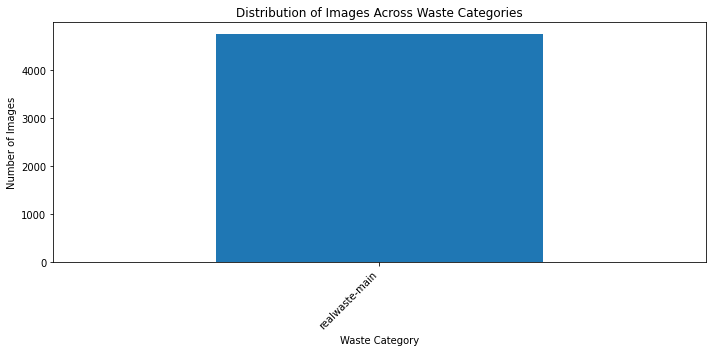

Category: realwaste-main | Image: Cardboard_1.jpg | Resolution: (524, 524) | Format: JPEG | Mode: RGB


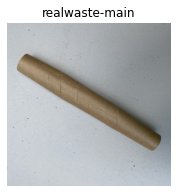

Category: realwaste-main | Image: Cardboard_10.jpg | Resolution: (524, 524) | Format: JPEG | Mode: RGB


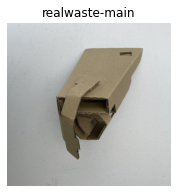

Category: realwaste-main | Image: Cardboard_100.jpg | Resolution: (524, 524) | Format: JPEG | Mode: RGB


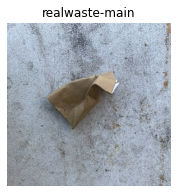

Category: realwaste-main | Image: Cardboard_101.jpg | Resolution: (524, 524) | Format: JPEG | Mode: RGB


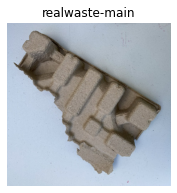

Category: realwaste-main | Image: Cardboard_102.jpg | Resolution: (524, 524) | Format: JPEG | Mode: RGB


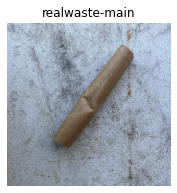

In [2]:

# TODO: Load and explore the RealWaste dataset
# - Dataset structure
# - Distribution of waste categories
# - Image characteristics (resolution, quality, background)

from pathlib import Path
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt

# Define the dataset path
data_dir = Path("realwaste")

# Check if the dataset folder exists
if not data_dir.exists():
    print("Dataset folder not found:", data_dir.resolve())
else:
    # Display dataset structure and count images in each category
    image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    category_counts = {}
    image_paths = []

    for category_folder in sorted(data_dir.iterdir()):
        if category_folder.is_dir():
            images = [
                file for file in category_folder.rglob("*")
                if file.is_file()
                and file.suffix.lower() in image_extensions
            ]

            category_counts[category_folder.name] = len(images)
            image_paths.extend(
                [(file, category_folder.name) for file in images]
            )

    # Display the distribution of waste categories
    category_counts_df = pd.DataFrame(
        category_counts.items(),
        columns=["Waste Category", "Number of Images"]
    )

    display(category_counts_df)
    print("Total images:", sum(category_counts.values()))

    # Plot the distribution of waste categories
    category_counts_df.plot(
        x="Waste Category",
        y="Number of Images",
        kind="bar",
        legend=False,
        figsize=(10, 5)
    )
    plt.title("Distribution of Images Across Waste Categories")
    plt.xlabel("Waste Category")
    plt.ylabel("Number of Images")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    # Inspect image characteristics using sample images
    if image_paths:
        sample_paths = image_paths[:5]

        for image_path, category in sample_paths:
            try:
                with Image.open(image_path) as img:
                    print(
                        f"Category: {category} | "
                        f"Image: {image_path.name} | "
                        f"Resolution: {img.size} | "
                        f"Format: {img.format} | "
                        f"Mode: {img.mode}"
                    )
                    plt.figure(figsize=(4, 3))
                    plt.imshow(img.convert("RGB"))
                    plt.title(category)
                    plt.axis("off")
                    plt.show()
            except Exception as e:
                print(f"Could not open {image_path.name}: {e}")
    else:
        print("No images were found. Check the dataset folder structure.")



### 1.2 Explore Text Datasets

,description,category,disposal_instruction,common_confusion,material_composition
0,soiled silver tablecloth,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
1,folded glass bottle leaking,Glass,"Remove caps, lids, and corks before recycling.",NaN,"Silica-based material, may contain additives f..."
2,large Supermarket vegetable waste with food re...,Food Organics,"If no compost available, place in general waste.",NaN,Biodegradable matter derived from plant or ani...
3,intact floral carpet piece,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
4,empty fun-sized purple apple core,Food Organics,Keep separate from recyclable materials.,Meat and dairy products may be restricted in s...,Biodegradable matter derived from plant or ani...


Dataset shape: (5000, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   description           5000 non-null   object
 1   category              5000 non-null   object
 2   disposal_instruction  5000 non-null   object
 3   common_confusion      2496 non-null   object
 4   material_composition  5000 non-null   object
dtypes: object(5)
memory usage: 195.4+ KB

Missing values:


description                0
category                   0
disposal_instruction       0
common_confusion        2504
material_composition       0
dtype: int64


Duplicate rows: 7

Category distribution:


category
Vegetation             600
Textile Trash          586
Cardboard              584
Miscellaneous Trash    578
Plastic                569
Glass                  551
Food Organics          518
Metal                  508
Paper                  506
Name: count, dtype: int64

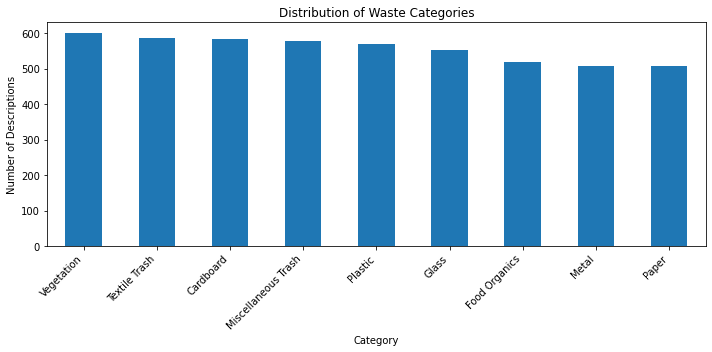

In [3]:
# TODO: Load and explore the waste description text data
# - Load waste_descriptions.csv
# - Analyze vocabulary and structure
# - Understand the distribution of categories


# Load and explore waste descriptions
descriptions_df = pd.read_csv("waste_descriptions.csv")

# Display the first five rows
display(descriptions_df.head())

# Display the dataset dimensions
print("Dataset shape:", descriptions_df.shape)

# Display column names and data types
descriptions_df.info()

# Check for missing values
print("\nMissing values:")
display(descriptions_df.isnull().sum())

# Check for duplicate rows
print("\nDuplicate rows:", descriptions_df.duplicated().sum())

# Explore category distribution
print("\nCategory distribution:")
display(descriptions_df["category"].value_counts())

# Visualize category distribution
descriptions_df["category"].value_counts().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Distribution of Waste Categories")
plt.xlabel("Category")
plt.ylabel("Number of Descriptions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [4]:
# TODO: Load and explore the waste policy documents
# - Load waste_policy_documents.csv
# - Understand document organization and language


# Load the policy documents
with open("waste_policy_documents.json", "r", encoding="utf-8") as file:
    policy_documents = json.load(file)

# Display the number of policy documents
print("Number of policy documents:", len(policy_documents))

# Convert the policy documents into a DataFrame
policies_df = pd.DataFrame(policy_documents)

# Display the first five policy documents
display(policies_df.head())

# Display column names and data types
policies_df.info()

# Check for missing values
print("\nMissing values per column:")
display(policies_df.isnull().sum())

# Explore policy types
if "policy_type" in policies_df.columns:
    print("\nPolicy type distribution:")
    display(policies_df["policy_type"].value_counts())

# Explore jurisdictions
if "jurisdiction" in policies_df.columns:
    print("\nJurisdictions covered:")
    display(policies_df["jurisdiction"].value_counts())

# Display the categories covered by each policy
if "categories_covered" in policies_df.columns:
    print("\nCategories covered by each policy:")
    display(policies_df[["policy_id", "categories_covered"]])


Number of policy documents: 14


,policy_id,policy_type,categories_covered,effective_date,document_text,jurisdiction
0,1,Textile Trash Recycling Guidelines,[Textile Trash],2023-11-04,TEXTILE RECYCLING GUIDELINES\n\nAcceptable Ite...,Metro City
1,2,Glass Recycling Guidelines,[Glass],2023-01-24,GLASS RECYCLING GUIDELINES\n\nAcceptable Items...,Metro City
2,3,Food Organics Recycling Guidelines,[Food Organics],2023-05-08,FOOD ORGANICS RECYCLING GUIDELINES\n\nAcceptab...,Metro City
3,4,Plastic Recycling Guidelines,[Plastic],2023-04-05,PLASTIC RECYCLING GUIDELINES\n\nAcceptable Ite...,Metro City
4,5,Vegetation Recycling Guidelines,[Vegetation],2023-12-04,VEGETATION RECYCLING GUIDELINES\n\nAcceptable ...,Metro City


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   policy_id           14 non-null     int64 
 1   policy_type         14 non-null     object
 2   categories_covered  14 non-null     object
 3   effective_date      14 non-null     object
 4   document_text       14 non-null     object
 5   jurisdiction        14 non-null     object
dtypes: int64(1), object(5)
memory usage: 800.0+ bytes

Missing values per column:


policy_id             0
policy_type           0
categories_covered    0
effective_date        0
document_text         0
jurisdiction          0
dtype: int64


Policy type distribution:


policy_type
Textile Trash Recycling Guidelines          1
Glass Recycling Guidelines                  1
Food Organics Recycling Guidelines          1
Plastic Recycling Guidelines                1
Vegetation Recycling Guidelines             1
Cardboard Recycling Guidelines              1
Metal Recycling Guidelines                  1
Paper Recycling Guidelines                  1
Miscellaneous Trash Recycling Guidelines    1
Municipal Waste Guidelines                  1
Residential Recycling Rules                 1
Commercial Recycling Standards              1
Multi-Unit Building Guidelines              1
Community Recycling Program                 1
Name: count, dtype: int64


Jurisdictions covered:


jurisdiction
Metro City    14
Name: count, dtype: int64


Categories covered by each policy:


,policy_id,categories_covered
0,1,[Textile Trash]
1,2,[Glass]
2,3,[Food Organics]
3,4,[Plastic]
4,5,[Vegetation]
5,6,[Cardboard]
6,7,[Metal]
7,8,[Paper]
8,9,[Miscellaneous Trash]
9,10,"[Plastic, Miscellaneous Trash, Vegetation]"


### 1.3 Create Data Pipelines

In [5]:
# Run this code to setup the images properly into train, validation, and test sets
# Set your data directory path - update this with your actual path
import pathlib
data_dir = pathlib.Path('realwaste/realwaste-main/RealWaste')
# Parameters
BATCH_SIZE = 32
IMG_HEIGHT = 224
IMG_WIDTH = 224

# Calculate the total number of classes automatically from the directory structure
num_classes = len([item for item in data_dir.glob('*') if item.is_dir()])
print(f"Number of classes: {num_classes}")

# List all class folders
class_names = sorted([item.name for item in data_dir.glob('*') if item.is_dir()])
print(f"Class names: {class_names}")

# Count all images
image_count = len(list(data_dir.glob('*/*.jpg'))) + len(list(data_dir.glob('*/*.png')))
print(f"Total images found: {image_count}")

# Create a dataset using tf.keras.utils.image_dataset_from_directory
# This will automatically split the data into training and validation sets
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="training",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="validation",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

# Create a separate test dataset by taking part of the validation set
# First, let's get the number of batches in the validation set
val_batches = tf.data.experimental.cardinality(validation_ds)
test_dataset = validation_ds.take(val_batches // 2)
validation_ds = validation_ds.skip(val_batches // 2)

print(f"Number of training batches: {tf.data.experimental.cardinality(train_ds)}")
print(f"Number of validation batches: {tf.data.experimental.cardinality(validation_ds)}")
print(f"Number of test batches: {tf.data.experimental.cardinality(test_dataset)}")

# Configure dataset for performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Number of classes: 9
Class names: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Total images found: 4752
Found 4752 files belonging to 9 classes.
Using 3802 files for training.
Found 4752 files belonging to 9 classes.
Using 950 files for validation.
Number of training batches: 119
Number of validation batches: 15
Number of test batches: 15


In [6]:
# TODO: Create a text preprocessing pipeline
# - Tokenization
# - Text cleaning
# - Split data into train and test
# - Create embeddings/features


import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Clean the waste descriptions
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

descriptions_df["cleaned_description"] = (
    descriptions_df["description"].apply(clean_text)
)

# Separate the text descriptions from their category labels
X = descriptions_df["cleaned_description"]
y = descriptions_df["category"]

# Split the data into training and testing sets
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Convert text into numerical TF-IDF features
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X_train_features = tfidf_vectorizer.fit_transform(X_train_text)
X_test_features = tfidf_vectorizer.transform(X_test_text)

# Display the results
print("Training examples:", len(X_train_text))
print("Testing examples:", len(X_test_text))
print("Number of TF-IDF features:", X_train_features.shape[1])
print("Training feature matrix shape:", X_train_features.shape)
print("Testing feature matrix shape:", X_test_features.shape)


Training examples: 4000
Testing examples: 1000
Number of TF-IDF features: 300
Training feature matrix shape: (4000, 300)
Testing feature matrix shape: (1000, 300)


In [7]:
# TODO: Prepare documents for RAG
# - Document preprocessing
# - Create embeddings for retrieval


# Prepare policy documents for retrieval
policy_texts = policies_df.apply(
    lambda row: (
        str(row["policy_type"]) + " " +
        str(row["categories_covered"]) + " " +
        str(row["jurisdiction"]) + " " +
        str(row["document_text"])
    ),
    axis=1
)

# Clean the policy document text
policy_texts = policy_texts.apply(clean_text)

# Create numerical TF-IDF features for policy retrieval
policy_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

policy_embeddings = policy_vectorizer.fit_transform(policy_texts)

# Display the results
print("Number of policy documents:", len(policy_texts))
print("Policy embeddings shape:", policy_embeddings.shape)
print("Number of retrieval features:", policy_embeddings.shape[1])

# Display a sample processed document
print("\nSample processed policy document:")
print(policy_texts.iloc[0][:500])


Number of policy documents: 14
Policy embeddings shape: (14, 292)
Number of retrieval features: 292

Sample processed policy document:
textile trash recycling guidelines textile trash metro city textile recycling guidelines acceptable items clean clothing all conditions towels sheets and linens fabric scraps curtains and cloth napkins handbags and backpacks made of fabric soft toys and stuffed animals non acceptable items wet or moldy textiles heavily soiled items carpets and rugs footwear items with significant non textile parts collection method place items in dedicated textile recycling bins or donate to local thrift stores 


## Part 2: Waste Material Classification with CNN

In this section, you will build a CNN model to classify waste materials from images.

### 2.1 Preprocess Images

In [8]:
# TODO: Implement image preprocessing
# - Apply the preprocessing pipeline created earlier


# Preprocess images for the MobileNetV2 model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

def preprocess_image(image, label):
    image = preprocess_input(image)
    return image, label

# Apply preprocessing to the training, validation, and test datasets
train_ds = train_ds.map(
    preprocess_image,
    num_parallel_calls=AUTOTUNE
)

validation_ds = validation_ds.map(
    preprocess_image,
    num_parallel_calls=AUTOTUNE
)

test_dataset = test_dataset.map(
    preprocess_image,
    num_parallel_calls=AUTOTUNE
)

print("Image preprocessing completed.")


Image preprocessing completed.


### 2.2 Implement CNN Model with Transfer Learning

In [9]:
# TODO: Select an appropriate base model and implement transfer learning
# - Choose from MobileNet, EfficientNet, etc.
# - Add custom classification layers for the 9 waste categories
# - Configure loss function and metrics


# Load the pretrained MobileNetV2 model
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers
base_model.trainable = False

# Add custom classification layers
inputs = tf.keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3))

x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    num_classes,
    activation="softmax"
)(x)

# Create the complete CNN model
model = tf.keras.Model(inputs=inputs, outputs=outputs)

# Configure the model for training
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the model architecture
model.summary()


Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 mobilenetv2_1.00_224 (Funct  (None, 7, 7, 1280)       2257984   
 ional)                                                          
                                                                 
 global_average_pooling2d (G  (None, 1280)             0         
 lobalAveragePooling2D)                                          
                                                                 
 dropout (Dropout)           (None, 1280)              0         
                                                                 
 dense (Dense)               (None, 9)                 11529     
                                                                 
Total params: 2,269,513
Trainable params: 11,529
Non-trainabl

### 2.3 Train and Evaluate the Model

In [10]:
# TODO: Train the CNN model
# - Use appropriate batch size and epochs
# - Implement regularization to prevent overfitting
# - Monitor training and validation metrics

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-6
)

history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=10,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/10
119/119 [==============================] - 183s 1s/step - loss: 1.3893 - accuracy: 0.5095 - val_loss: 0.8232 - val_accuracy: 0.7064 - lr: 0.0010
Epoch 2/10
119/119 [==============================] - 139s 1s/step - loss: 0.8239 - accuracy: 0.7062 - val_loss: 0.6862 - val_accuracy: 0.7532 - lr: 0.0010
Epoch 3/10
119/119 [==============================] - 143s 1s/step - loss: 0.6669 - accuracy: 0.7685 - val_loss: 0.6117 - val_accuracy: 0.7809 - lr: 0.0010
Epoch 4/10
119/119 [==============================] - 139s 1s/step - loss: 0.6036 - accuracy: 0.7896 - val_loss: 0.5845 - val_accuracy: 0.7957 - lr: 0.0010
Epoch 5/10
119/119 [==============================] - 139s 1s/step - loss: 0.5377 - accuracy: 0.8106 - val_loss: 0.5658 - val_accuracy: 0.7894 - lr: 0.0010
Epoch 6/10
119/119 [==============================] - 131s 1s/step - loss: 0.5042 - accuracy: 0.8233 - val_loss: 0.5622 - val_accuracy: 0.8043 - lr: 0.0010
Epoch 7/10
119/119 [==============================] - 139s 1s/st

15/15 [==============================] - 33084s 2363s/step - loss: 0.5244 - accuracy: 0.8271
Test Loss: 0.5244
Test Accuracy: 0.8271
15/15 [==============================] - 48s 2s/step


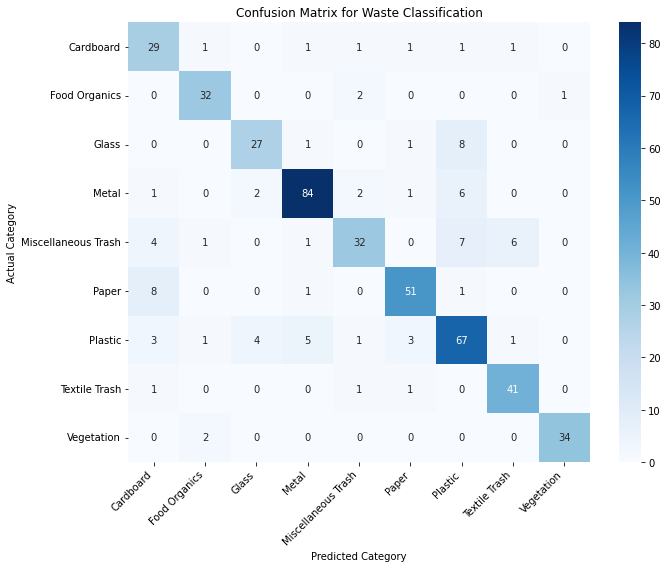

                     precision    recall  f1-score   support

          Cardboard       0.63      0.83      0.72        35
      Food Organics       0.86      0.91      0.89        35
              Glass       0.82      0.73      0.77        37
              Metal       0.90      0.88      0.89        96
Miscellaneous Trash       0.82      0.63      0.71        51
              Paper       0.88      0.84      0.86        61
            Plastic       0.74      0.79      0.77        85
      Textile Trash       0.84      0.93      0.88        44
         Vegetation       0.97      0.94      0.96        36

           accuracy                           0.83       480
          macro avg       0.83      0.83      0.83       480
       weighted avg       0.83      0.83      0.83       480



In [11]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluate the model on the test dataset
test_loss, test_accuracy = model.evaluate(test_dataset)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Generate predictions
y_pred_prob = model.predict(test_dataset)
y_pred = np.argmax(y_pred_prob, axis=1)

# Get the true labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_dataset
])

# Convert one-hot encoded labels to class numbers
y_true = np.argmax(y_true, axis=1)

# Generate the confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Confusion Matrix for Waste Classification")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Display the classification report
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

### 2.4 Fine-tune the Model

In [12]:
# TODO: Tune model parameters to improve performance
# - Adjust learning rate
# - Add regularization, dropout
# - Modify architecture if needed

# Unfreeze the pretrained model for fine-tuning
base_model.trainable = True

# Freeze earlier layers and fine-tune only the last 20 layers
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stability
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a lower learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Fine-tune the model
history_fine = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=5
)

Epoch 1/5
119/119 [==============================] - 220s 2s/step - loss: 0.3605 - accuracy: 0.8719 - val_loss: 0.5163 - val_accuracy: 0.8064
Epoch 2/5
119/119 [==============================] - 167s 1s/step - loss: 0.3202 - accuracy: 0.8885 - val_loss: 0.4946 - val_accuracy: 0.8213
Epoch 3/5
119/119 [==============================] - 149s 1s/step - loss: 0.2873 - accuracy: 0.9008 - val_loss: 0.4892 - val_accuracy: 0.8340
Epoch 4/5
119/119 [==============================] - 154s 1s/step - loss: 0.2460 - accuracy: 0.9156 - val_loss: 0.4792 - val_accuracy: 0.8340
Epoch 5/5
119/119 [==============================] - 149s 1s/step - loss: 0.2231 - accuracy: 0.9250 - val_loss: 0.4822 - val_accuracy: 0.8170


## Part 3: Waste Description Classification

In this section, you will build a text classification model to categorize waste based on descriptions.

### 3.1 Preprocess Text Data

In [13]:
# TODO: Implement text preprocessing
# - Apply the text preprocessing pipeline created earlier

# Reuse the text preprocessing pipeline created in Part 1.3

print("Training text features shape:", X_train_features.shape)
print("Testing text features shape:", X_test_features.shape)

print("\nTraining labels:", len(y_train))
print("Testing labels:", len(y_test))

print("\nSample processed text features:")
print(X_train_features[0])

print("\nWaste categories:")
print(sorted(y_train.unique()))

Training text features shape: (4000, 300)
Testing text features shape: (1000, 300)

Training labels: 4000
Testing labels: 1000

Sample processed text features:
  (0, 104)	0.7169596351407614
  (0, 197)	0.49982387298097786
  (0, 94)	0.4859475049602804

Waste categories:
['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']


### 3.2 Implement Text Classification Model

In [14]:
# TODO: Choose and implement a text classification model
# Option A: Traditional ML model (Naive Bayes, Random Forest, etc.)
# Option B: Fine-tune a transformer-based model (BERT, DistilBERT, etc.)

from sklearn.naive_bayes import MultinomialNB

# Initialize the text classification model
text_model = MultinomialNB()

print("Text classification model initialized successfully.")

Text classification model initialized successfully.


### 3.3 Train and Evaluate the Model

In [15]:
# TODO: Train the text classification model
# - Use appropriate training parameters
# - Monitor training progress

from sklearn.metrics import accuracy_score, classification_report

# Train the text classification model
text_model.fit(X_train_features, y_train)

# Predict waste categories for the testing data
y_pred_text = text_model.predict(X_test_features)

# Calculate model accuracy
text_accuracy = accuracy_score(y_test, y_pred_text)

print(f"Text Classification Accuracy: {text_accuracy:.4f}")

# Display performance for each waste category
print("\nClassification Report:")
print(classification_report(y_test, y_pred_text, zero_division=0))

Text Classification Accuracy: 0.9960

Classification Report:
                     precision    recall  f1-score   support

          Cardboard       1.00      1.00      1.00       117
      Food Organics       1.00      0.99      1.00       104
              Glass       1.00      1.00      1.00       110
              Metal       1.00      0.99      1.00       101
Miscellaneous Trash       1.00      0.98      0.99       116
              Paper       1.00      1.00      1.00       101
            Plastic       0.97      1.00      0.99       114
      Textile Trash       1.00      1.00      1.00       117
         Vegetation       0.99      1.00      1.00       120

           accuracy                           1.00      1000
          macro avg       1.00      1.00      1.00      1000
       weighted avg       1.00      1.00      1.00      1000



Test Accuracy: 0.9960


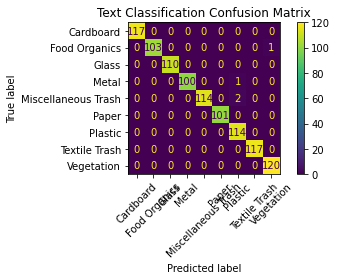

Number of incorrect predictions: 4

Sample misclassified descriptions:
4451                          massive black soda can
4016    patterned supermarket vegetable waste sealed
22                      broken mini eco friendly toy
3992                green homemade toy with contents
Name: cleaned_description, dtype: object


In [16]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate accuracy on the test set
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_text):.4f}")

# Generate the confusion matrix
cm_text = confusion_matrix(y_test, y_pred_text, labels=text_model.classes_)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_text,
    display_labels=text_model.classes_
)
disp.plot(xticks_rotation=45)
plt.title("Text Classification Confusion Matrix")
plt.tight_layout()
plt.show()

# Identify incorrectly classified descriptions
errors = X_test_text[y_test != y_pred_text]

print("Number of incorrect predictions:", len(errors))
print("\nSample misclassified descriptions:")
print(errors.head())

### 3.4 Create Classification Function

In [17]:
# TODO: Create a function that takes a text description and returns the predicted waste category

def classify_waste_description(description):
    """
    Classifies a waste description into an appropriate category.

    Args:
        description (str): Text description of waste item

    Returns:
        str: Predicted waste category
    """
    cleaned_description = clean_text(description)

    description_features = tfidf_vectorizer.transform(
        [cleaned_description]
    )

    predicted_category = text_model.predict(description_features)[0]

    return predicted_category
print(classify_waste_description("empty plastic water bottle"))
print(classify_waste_description("used cardboard box"))
print(classify_waste_description("banana peels and leftover food"))
pass

Plastic
Cardboard
Food Organics


## Part 4: Recycling Instruction Generation with RAG

In this section, you will implement a Retrieval-Augmented Generation (RAG) system to generate recycling instructions.

### 4.1 Preprocess Documents for Retrieval

In [18]:
# TODO: Prepare documents for retrieval
# - Process policy documents and disposal instructions
# - Create embeddings for efficient retrieval

# Reuse the processed policy documents and TF-IDF embeddings
retrieval_documents = policy_texts.tolist()
retrieval_embeddings = policy_embeddings

print("Number of retrieval documents:", len(retrieval_documents))
print("Retrieval embeddings shape:", retrieval_embeddings.shape)
print("\nSample retrieval document:")
print(retrieval_documents[0][:500])

Number of retrieval documents: 14
Retrieval embeddings shape: (14, 292)

Sample retrieval document:
textile trash recycling guidelines textile trash metro city textile recycling guidelines acceptable items clean clothing all conditions towels sheets and linens fabric scraps curtains and cloth napkins handbags and backpacks made of fabric soft toys and stuffed animals non acceptable items wet or moldy textiles heavily soiled items carpets and rugs footwear items with significant non textile parts collection method place items in dedicated textile recycling bins or donate to local thrift stores 


### 4.2 Implement RAG-based System

In [33]:
# TODO: Select a pre-trained language model and implement RAG
# - Choose an appropriate language model
# - Create a retrieval mechanism

from sklearn.metrics.pairwise import cosine_similarity
from transformers import pipeline

# Load a pre-trained language model
rag_generator = pipeline(
    "text2text-generation",
    model="google/flan-t5-small"
)

# Create a retrieval mechanism
def retrieve_policy_documents(query, top_k=1):
    query = clean_text(query)
    query_embedding = policy_vectorizer.transform([query])

    similarities = cosine_similarity(
        query_embedding,
        retrieval_embeddings
    ).flatten()

    top_indices = similarities.argsort()[::-1][:top_k]

    retrieved_docs = [
        retrieval_documents[i]
        for i in top_indices
    ]

    return retrieved_docs


# Generate an answer using retrieved policy documents
def generate_recycling_instruction(query):
    retrieved_docs = retrieve_policy_documents(query)

    if not retrieved_docs:
        return "No relevant policy information was found."

    context = "\n\n".join(retrieved_docs)

    prompt = (
        "Answer the question using only the policy information below. "
        "If the information is insufficient, say so.\n\n"
        f"Policy information:\n{context}\n\n"
        f"Question: {query}\n"
        "Answer:"
    )

    response = rag_generator(
        prompt,
        max_new_tokens=120,
        do_sample=False
    )

    return response[0]["generated_text"]


print("RAG system initialized successfully.")

RAG system initialized successfully.


### 4.3 Adjust and Evaluate the System

In [51]:
# TODO: Train the RAG-based system
# - Adjust sampling methods/parameters

# Adjust the generation parameters for more consistent answers


def generate_recycling_instruction(query):
    retrieved_docs = retrieve_policy_documents(query)

    if not retrieved_docs:
        return "No relevant policy information was found."

    formatted_answer = "RECYCLING INSTRUCTIONS\n"

    for i, document in enumerate(retrieved_docs, start=1):
        formatted_answer += (
            f"\nRelevant Policy {i}:\n"
            f"{document}\n"
        )

    return formatted_answer



print(generate_recycling_instruction(
    "How should I dispose of a plastic bottle?"
))


RECYCLING INSTRUCTIONS

Relevant Policy 1:
plastic recycling guidelines plastic metro city plastic recycling guidelines acceptable items pet bottles and containers code 1 hdpe containers code 2 pp containers code 5 clean plastic packaging non acceptable items plastic bags and film polystyrene foam code 6 containers with food residue mixed material packaging black plastic containers collection method place in dedicated recycling bins check local guidelines for specific plastic types accepted preparation instructions rinse containers remove lids and caps recycle separately check for recycling codes 1 7 benefits plastic recycling reduces petroleum consumption and greenhouse gas emissions



In [52]:
# TODO: Evaluate the quality of generated instructions
# - Test with various waste categories
# - Assess relevance and accuracy

# Test the RAG system with different waste categories
test_questions = [
    "How should I dispose of a plastic bottle?",
    "How should I recycle cardboard?",
    "How should I dispose of food waste?",
    "How should I dispose of textile waste?",
    "How should I dispose of glass?"
]

for question in test_questions:
    print("=" * 60)
    print("Question:", question)

    answer = generate_recycling_instruction(question)

    print("Generated instruction:", answer)
    print()

Question: How should I dispose of a plastic bottle?
Generated instruction: RECYCLING INSTRUCTIONS

Relevant Policy 1:
plastic recycling guidelines plastic metro city plastic recycling guidelines acceptable items pet bottles and containers code 1 hdpe containers code 2 pp containers code 5 clean plastic packaging non acceptable items plastic bags and film polystyrene foam code 6 containers with food residue mixed material packaging black plastic containers collection method place in dedicated recycling bins check local guidelines for specific plastic types accepted preparation instructions rinse containers remove lids and caps recycle separately check for recycling codes 1 7 benefits plastic recycling reduces petroleum consumption and greenhouse gas emissions


Question: How should I recycle cardboard?
Generated instruction: RECYCLING INSTRUCTIONS

Relevant Policy 1:
cardboard recycling guidelines cardboard metro city cardboard recycling guidelines acceptable items corrugated cardboard 

### 4.4 Create Instruction Generation Function

In [53]:
# TODO: Create a function that takes a waste category and generates recycling instructions

def generate_recycling_instructions(waste_category):
    """
    Generates detailed recycling instructions for a given waste category.

    Args:
        waste_category (str): Waste category

    Returns:
        str: Detailed recycling instructions
        list: Relevant policy documents
    """
   
    # Retrieve relevant policy documents for the waste category

    query = f"How should I dispose of {waste_category} waste?"
    retrieved_docs = retrieve_policy_documents(query)

    if not retrieved_docs:
        return "No relevant policy information was found.", []

    # Generate recycling instructions using the retrieved policies
    instructions = generate_recycling_instruction(query)

    return instructions, retrieved_docs


    pass

## Part 5: Integrated Waste Management Assistant

In this section, you will integrate all three models into a unified waste management assistant.

### 5.1 Design Integration Architecture

In [56]:
# TODO: Design an architecture that integrates all three models
# - Create interfaces between components
# - Handle input/output flow


print("WASTE MANAGEMENT ASSISTANT ARCHITECTURE")
print("-" * 45)

print("1. User provides an input")
print("   - Image of waste")
print("   - Text description of waste")

print("\n2. Input processing")
print("   - Image input -> CNN image classifier")
print("   - Text input  -> Text classification model")

print("\n3. Waste category prediction")
print("   - Identify the predicted waste category")

print("\n4. Recycling instruction generation")
print("   - Retrieve relevant policy documents using RAG")
print("   - Generate recycling instructions")

print("\n5. Final output")
print("   - Waste category")
print("   - Prediction confidence")
print("   - Recycling instructions")


WASTE MANAGEMENT ASSISTANT ARCHITECTURE
---------------------------------------------
1. User provides an input
   - Image of waste
   - Text description of waste

2. Input processing
   - Image input -> CNN image classifier
   - Text input  -> Text classification model

3. Waste category prediction
   - Identify the predicted waste category

4. Recycling instruction generation
   - Retrieve relevant policy documents using RAG
   - Generate recycling instructions

5. Final output
   - Waste category
   - Prediction confidence
   - Recycling instructions


### 5.2 Implement Integrated Assistant

In [60]:
# TODO: Implement the integrated waste management assistant

def waste_management_assistant(input_data, input_type="image"):
    """
    Integrated waste management assistant that processes either images or text descriptions
    and returns waste classification and recycling instructions.

    Args:
        input_data: Either an image file path/array or a text description
        input_type (str): Type of input - "image" or "text"

    Returns:
        dict: Dictionary containing waste category, confidence, and recycling instructions
    """
    
    import numpy as np
    from PIL import Image
    from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
    if input_type == "text":
        # Classify the written description
        cleaned_description = clean_text(input_data)
        text_features = tfidf_vectorizer.transform(
            [cleaned_description]
        )

        waste_category = text_model.predict(text_features)[0]
        confidence = float(
            np.max(text_model.predict_proba(text_features)[0])
        )

    elif input_type == "image":
        # Load the image from a file path or image array
        if isinstance(input_data, (str, bytes)):
            image = Image.open(input_data).convert("RGB")
        elif isinstance(input_data, Image.Image):
            image = input_data.convert("RGB")
        else:
            image_array = np.asarray(input_data).astype("uint8")
            image = Image.fromarray(image_array).convert("RGB")

        # Resize and preprocess the image for MobileNetV2
        image = image.resize((IMG_WIDTH, IMG_HEIGHT))
        image_array = np.asarray(image, dtype=np.float32)
        image_array = np.expand_dims(image_array, axis=0)
        image_array = preprocess_input(image_array)

        # Predict the waste category
        predictions = model.predict(image_array, verbose=0)[0]
        predicted_index = int(np.argmax(predictions))

        waste_category = class_names[predicted_index]
        confidence = float(predictions[predicted_index])

    else:
        raise ValueError(
            "input_type must be either 'image' or 'text'."
        )

    # Retrieve recycling instructions for the predicted category
    instructions, policy_docs = generate_recycling_instructions(
        waste_category
    )

    # Return all results in a dictionary
    return {
        "waste_category": waste_category,
        "confidence": confidence,
        "recycling_instructions": instructions,
        "policy_documents": policy_docs
    }

    pass

### 5.3 Evaluate the Integrated System

In [65]:

# TODO: Evaluate the integrated system on test cases
# - Test with images from test dataset
# - Test with text descriptions from test dataset
# - Assess overall performance


# Test the integrated assistant using text descriptions
text_test_cases = [
    "empty plastic water bottle",
    "used cardboard box",
    "banana peels and leftover food",
    "old clothes and fabric scraps",
    "broken glass bottle"
]

print("TEXT INPUT EVALUATION")
print("=" * 50)

for description in text_test_cases:
    result = waste_management_assistant(
        description,
        input_type="text"
    )

    print("\nInput:", description)
    print("Predicted category:", result["waste_category"])
    print(f"Confidence: {result['confidence']:.2%}")
    print(
        "Policy documents retrieved:",
        len(result["policy_documents"])
    )


# Test the integrated assistant using images from different categories
print("\n\nIMAGE INPUT EVALUATION")
print("=" * 50)

# Select one image from each available category
sample_images = []
seen_categories = set()

for image_path, _ in image_paths:
    filename = image_path.stem.lower()

    actual_category = None

    # Match the filename to one of the known class names
    for category in class_names:
        category_prefix = category.replace(" ", "_").lower()

        if filename.startswith(category_prefix + "_"):
            actual_category = category
            break

    if actual_category is None:
        continue

    if actual_category not in seen_categories:
        sample_images.append((image_path, actual_category))
        seen_categories.add(actual_category)

    if len(sample_images) >= len(class_names):
        break

print("Number of categories sampled:", len(sample_images))
print("Categories:", sorted(seen_categories))

# Evaluate the selected images
image_results = []

for image_path, actual_category in sample_images:
    try:
        result = waste_management_assistant(
            str(image_path),
            input_type="image"
        )

        predicted_category = result["waste_category"]

        image_results.append({
            "Image": image_path.name,
            "Actual category": actual_category,
            "Predicted category": predicted_category,
            "Correct": (
                actual_category.strip().lower()
                == predicted_category.strip().lower()
            ),
            "Confidence": result["confidence"]
        })

    except Exception as e:
        print(f"Could not process {image_path}: {e}")

# Display results and calculate sample accuracy
if image_results:
    image_results_df = pd.DataFrame(image_results)
    display(image_results_df)

    image_accuracy = image_results_df["Correct"].mean()

    print(
        f"\nSample image accuracy: {image_accuracy:.2%}"
    )
else:
    print("No images were successfully evaluated.")


TEXT INPUT EVALUATION

Input: empty plastic water bottle
Predicted category: Plastic
Confidence: 94.40%
Policy documents retrieved: 1

Input: used cardboard box
Predicted category: Cardboard
Confidence: 88.62%
Policy documents retrieved: 1

Input: banana peels and leftover food
Predicted category: Food Organics
Confidence: 83.64%
Policy documents retrieved: 1

Input: old clothes and fabric scraps
Predicted category: Textile Trash
Confidence: 82.17%
Policy documents retrieved: 1

Input: broken glass bottle
Predicted category: Glass
Confidence: 84.12%
Policy documents retrieved: 1


IMAGE INPUT EVALUATION
Number of categories sampled: 6
Categories: ['Cardboard', 'Glass', 'Metal', 'Paper', 'Plastic', 'Vegetation']


,Image,Actual category,Predicted category,Correct,Confidence
0,Cardboard_1.jpg,Cardboard,Cardboard,True,0.921905
1,Glass_1.jpg,Glass,Glass,True,0.984536
2,Metal_1.jpg,Metal,Metal,True,0.868565
3,Paper_1.jpg,Paper,Paper,True,0.748606
4,Plastic_1.jpg,Plastic,Plastic,True,0.991908
5,Vegetation_1.jpg,Vegetation,Vegetation,True,0.999925



Sample image accuracy: 100.00%


## Submission Guidelines

1. Make sure all code cells are properly commented and annotated
2. Ensure that all functions are implemented and working correctly
3. Verify that all evaluation metrics are calculated and analyzed
4. Double-check that the integrated system works as expected
5. Submit your completed and annotated Jupyter notebook file

Remember to demonstrate your understanding of the underlying concepts and provide justification for your design decisions throughout the notebook.